In [1]:
import os
import sys
import requests
import datetime as dt
import numpy as np
from dotenv import load_dotenv
from pathlib import Path
import requests
import pandas as pd
import talib as ta
import plotly.graph_objs as go

import ipywidgets as widgets
from ipywidgets import Dropdown, Text, Button, Output
from IPython.display import display

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.reques_api import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension

In [2]:
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()

#### WTIの時系列データを取得

In [3]:
wti = 'CL=F'
start = '1999-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
response = request_api.update_commodity_timeseries_data(
    code=wti,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [4]:
wti_df = request_api.get_commodity_time_series_data(
    code=wti,
    market=None,
    start=start,
    end=end
)
wti_df.head()

取得件数: 6559


,id,commodity_id,commodity_code,commodity_market,date,open,high,low,close,adj_close,...,rci26,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,6530,2,CL=F,None,2000-08-23,32.049999,32.799999,31.950001,31.950001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,6531,2,CL=F,None,2000-08-24,31.629999,32.240002,31.400000,31.900000,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,6532,2,CL=F,None,2000-08-25,32.049999,32.099998,31.320000,31.700001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,6533,2,CL=F,None,2000-08-28,32.869999,32.919998,31.860001,32.040001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,6534,2,CL=F,None,2000-08-29,32.720001,33.029999,32.560001,32.820000,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### S&P500の時系列データを取得

In [5]:
sp500 = '^GSPC'

response = request_api.update_stock_timeseries_data(
    code=sp500,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [6]:
sp_timeseries_df = request_api.get_stock_time_series_data(
    code=sp500,
    market=None,
    start=start,
    end=end
)
sp_timeseries_df.head()

取得件数: 7013


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1064856,^GSPC,None,1998-11-17,1139.319946,1151.709961,1129.670044,1135.869995,705200000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1064857,^GSPC,None,1998-11-18,1144.479980,1144.520020,1133.069946,1139.319946,652510000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1064858,^GSPC,None,1998-11-19,1152.609985,1155.099976,1144.420044,1144.479980,671000000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1064859,^GSPC,None,1998-11-20,1163.550049,1163.550049,1152.609985,1152.609985,721200000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1064860,^GSPC,None,1998-11-23,1188.209961,1188.209961,1163.550049,1163.550049,774100000,1147.165991,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### FTIの時系列データを取得

In [7]:
fti = 'FTI'

response = request_api.update_stock_timeseries_data(
    code=fti,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [8]:
fti_timeseries_df = request_api.get_stock_time_series_data(
    code=fti,
    market=None,
    start=start,
    end=end
)
fti_timeseries_df

取得件数: 6364


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1118065,FTI,None,2001-06-15,3.532829,3.634692,3.516661,3.524745,6636134,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1118066,FTI,None,2001-06-18,3.476240,3.557082,3.463305,3.532830,4323379,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1118067,FTI,None,2001-06-19,3.371144,3.500492,3.363060,3.500492,5387290,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1118068,FTI,None,2001-06-20,3.363060,3.363060,3.201374,3.354975,7024819,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1118069,FTI,None,2001-06-21,3.233711,3.346890,3.232094,3.346890,5805005,3.451987,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6359,1124424,FTI,None,2026-09-30,67.919998,69.080002,67.800003,69.080002,2671100,70.394002,...,71.249824,-1.630667,False,NaN,NaN,NaN,NaN,NaN,NaN,False
6360,1124425,FTI,None,2026-10-01,68.849998,69.010002,67.309998,67.680000,2174400,69.624002,...,70.715730,-8.913173,False,NaN,NaN,NaN,NaN,NaN,NaN,False
6361,1124426,FTI,None,2026-10-02,68.820000,69.529999,67.959999,68.410004,2745800,69.282002,...,70.261341,-15.896867,False,NaN,NaN,NaN,NaN,NaN,NaN,False
6362,1124427,FTI,None,2026-10-05,70.250000,72.209999,68.349998,69.019997,3295800,68.676001,...,69.874363,-19.969265,False,NaN,NaN,NaN,NaN,NaN,NaN,True


#### チャート

In [9]:
def stock_prices_and_oil_prices(
        code: str,
        name: str,
        start: str,
        end: str,
        df_sp: pd.DataFrame | None = None,
        df_wti: pd.DataFrame | None = None,
        #df_silver: pd.DataFrame | None = None,
    ):
    # /api/v1/time_series_data/stock/
    response = request_api.get_stock_time_series_data(
        code=code,
        market=None,
        start=start,
        end=end
    )
    df_stock = pd.DataFrame(response)

    # S&P500を統合
    if df_sp is not None:
        df_sp_tmp = df_sp.copy() if df_sp is not None else pd.DataFrame()
        if "date" not in df_sp_tmp.columns:
            df_sp_tmp = df_sp_tmp.reset_index()

        df_sp_tmp["date"] = pd.to_datetime(df_sp_tmp["date"])
        df_sp_tmp = df_sp_tmp.set_index("date")
        df_sp_tmp = df_sp_tmp.loc[start:end]

    # WTI原油価格を統合
    if df_wti is not None:
        df_wti_tmp = df_wti.copy() if df_wti is not None else pd.DataFrame()
        if "date" not in df_wti_tmp.columns:
            df_wti_tmp = df_wti_tmp.reset_index()
        df_wti_tmp["date"] = pd.to_datetime(df_wti_tmp["date"])
        df_wti_tmp = df_wti_tmp.set_index("date")
        df_wti_tmp = df_wti_tmp.loc[start:end]

    # 株価時系列データを整形
    df = df_stock.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")
    df = df.loc[start:end]


    # インデックスを揃えて結合
    if df_sp is not None:
        df["MA50_SP"] = df_sp_tmp["ma50"].reindex(df.index)
        df["MA200_SP"] = df_sp_tmp["ma200"].reindex(df.index)
    if df_wti is not None:
        df["MA50_WTI"] = df_wti_tmp["ma50"].reindex(df.index)
        df["MA200_WTI"] = df_wti_tmp["ma200"].reindex(df.index)

    show_plot = ShowPlot()
    fig = show_plot.create_basic_chart(
        df=df.reset_index(),
        code=code,
        name=name,
        start=start,
        end=end,
        ma5=False,
        ma25=False,
        ma50=True,
        ma100=False,
        ma150=False,
        ma200=True,
    )
    # ★ 2つのY軸を定義（左：HYMC、右：SP500 & GOLD）
    fig.update_layout(
        yaxis=dict(
            title=f"{name} Price",
            side="left"
        ),
        yaxis2=dict(
            title="SP500 / WTI",
            overlaying="y",
            side="right"
        )
    )

    # --- SP500（右軸） ---
    if df_sp is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_SP"],
                name="SP_MA50",
                line={"color": "blue", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_SP"],
                name="SP_MA200",
                line={"color": "gray", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    # --- WTI（右軸） ---
    if df_wti is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_WTI"],
                name="WTI_MA50",
                line={"color": "orange", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_WTI"],
                name="WTI_MA200",
                line={"color": "yellow", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    return fig

In [10]:
name = "Technip FMC"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_oil_prices(
    code=fti,
    name=name,
    start=start,
    end=end,
    df_sp=None,
    df_wti=wti_df
)
fig.show()

取得件数: 648


In [11]:
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"{fti}_{start}_{end}.png"
fig.write_image(str(output_path), width=1600, height=900, scale=2)
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/FTI_2025-01-01_2026-10-07.png


#### 株価のみのチャート

In [12]:
name = "Technip FMC"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_oil_prices(
    code=fti,
    name=name,
    start=start,
    end=end,
    df_sp=None,
    df_wti=None
)
fig.show()

取得件数: 648


#### 時系列データを保存

In [13]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{fti}_data_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"

df = fti_timeseries_df.copy()
df = df.reset_index()
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df = df.loc['2026-01-01':end]
df.to_csv(output_path)
df.head()

,index,id,stock_code,stock_market,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,6173,1124238,FTI,None,47.211102,47.260996,44.406974,44.416952,3100300,44.776203,...,44.475865,82.463929,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-05,6174,1124239,FTI,None,48.189060,48.997365,47.041463,48.757868,4581400,45.620435,...,44.347533,82.463929,True,45.620435,NaN,0.570677,NaN,NaN,NaN,False
2026-01-06,6175,1124240,FTI,None,48.238953,48.897573,47.610268,48.598201,2864600,46.358889,...,44.346132,82.455391,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-07,6176,1124241,FTI,None,49.077198,49.985296,48.648097,48.817739,5050300,47.149234,...,44.326736,82.455391,True,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-08,6177,1124242,FTI,None,49.336651,49.685922,47.869726,49.326673,3406000,47.983487,...,44.307579,82.455391,True,NaN,NaN,NaN,NaN,NaN,NaN,False


#### Fibonacci Extension

{'fib_levels_down': {'1.000': np.float64(63.50019519216035),
  '1.272': np.float64(58.82184911450609),
  '1.382': np.float64(56.929870921337084),
  '1.618': np.float64(52.87071770690177)},
 'fib_levels_up': {'1.272': np.float64(85.37834302589644),
  '1.382': np.float64(87.27032121906545),
  '1.618': np.float64(91.32947443350076),
  '2.000': np.float64(97.89979870432403)},
 'swing_high': np.float64(80.69999694824219),
 'swing_low': np.float64(63.50019519216035),
 'df_with_fib':           date  index       id stock_code stock_market       open       high  \
 0   2026-01-02   6173  1124238        FTI         None  47.211102  47.260996   
 1   2026-01-05   6174  1124239        FTI         None  48.189060  48.997365   
 2   2026-01-06   6175  1124240        FTI         None  48.238953  48.897573   
 3   2026-01-07   6176  1124241        FTI         None  49.077198  49.985296   
 4   2026-01-08   6177  1124242        FTI         None  49.336651  49.685922   
 ..         ...    ...      ...  

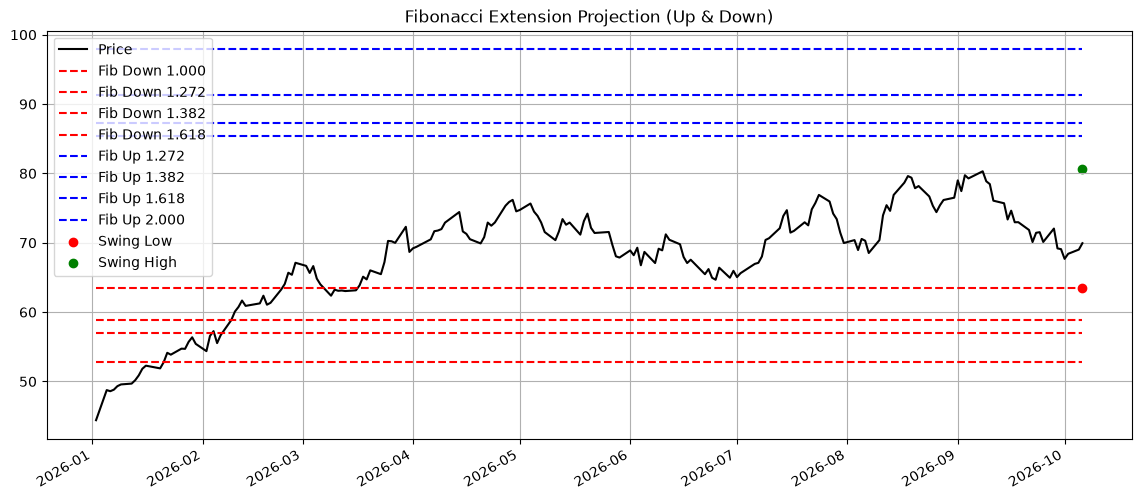

In [14]:
fib_result = fibonacci_extension.compute_fibonacci_extension(df.copy().reset_index())
fib_result

In [15]:
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{fti}_fibonacci_extension_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
fib_result["plot_obj"].savefig(output_path, dpi=300, bbox_inches="tight")

#### 財務データ

In [16]:
response = request_api.update_corp_finance_data(
    code=fti,
    market=None
)
response

{'result': True}

In [17]:
fti_financials_data = request_api.get_corp_financials_data(code=fti, market=None)
fti_balance_sheet_data = request_api.get_corp_balance_sheet_data(code=fti, market=None)
fti_cash_flow_data = request_api.get_corp_cash_flow_data(code=fti, market=None)
fti_earnings_data = request_api.get_corp_earnings_data(code=fti, market=None)
fti_quarterly_earnings_data = request_api.get_corp_quarterly_earnings_data(code=fti, market=None)

In [18]:
# ４年分の財務データ
fti_financials_data_df = pd.DataFrame(fti_financials_data['results'])
# ４年分のバランスシート
fti_balance_sheet_data_df = pd.DataFrame(fti_balance_sheet_data['results'])
# ４年分のキャッシュフロー
fti_cash_flow_data_df = pd.DataFrame(fti_cash_flow_data['results'])
# ４年分の収益データ
fti_earnings_data_df = pd.DataFrame(fti_earnings_data['results'])
# ４年分の四半期収益データ
fti_quarterly_earnings_data_df = pd.DataFrame(fti_quarterly_earnings_data['results'])

In [19]:
"""
◆ 1. 株価・市場データ
• 現在株価（Price）
• 時価総額（Market Cap）
• 出来高（Volume）
• 52週高値・安値
• Beta（ボラティリティ指標）ß
"""
stock_prices_market_data.stock_prices_and_market_data(
    code=fti,
    market=None,
    bs_df=fti_balance_sheet_data_df
)

取得件数: 461
取得件数: 461
取得件数: 460
取得件数: 460
取得件数: 458
取得件数: 458
取得件数: 459
取得件数: 459
取得件数: 458
取得件数: 458


,close,market_cap,shares_outstanding,higher_rate_par_52_weeks,lower_rate_par_52_weeks,beta
0,9.356760,NaN,NaN,10.480000,3.204566,1.182638
1,8.814952,3.897972e+09,442200000.0,12.811064,5.367327,1.133097
2,7.453532,3.226634e+09,432900000.0,22.372851,5.367327,1.017725
3,14.495701,6.133131e+09,423100000.0,32.377775,11.792448,0.963960
4,21.836502,8.749886e+09,400700000.0,47.231066,21.029201,1.239459


In [20]:
"""
◆ 2. 財務データ（Financials）+ EPS（Earnings Per Share）+ PBR（Price-to-Book Ratio）
• 売上高（Revenue）
• 営業利益（Operating Income）
• 純利益（Net Income）
• EBITDA（企業による）
• 総資産（Total Assets）
• 総負債（Total Liabilities）
• 現金（Cash）
• 希釈EPS（Diluted EPS）
• 基本EPS（Basic EPS）
• 営業キャッシュフロー（Operating Cash Flow）
• フリーキャッシュフロー（Free Cash Flow）
"""
financial_df = financial.calc_financial(
    code = fti,
    market = None,
)
financial_df.to_markdown()

取得件数: 6364


'|    | date                |      revenue |    earnings |   total_assets |   total_debt |   cash_and_cash_equivalents |     EBITDA |   operating_income |   basic_eps |   diluted_eps |   operating_cash_flow |   free_cash_flow |\n|---:|:--------------------|-------------:|------------:|---------------:|-------------:|----------------------------:|-----------:|-------------------:|------------:|--------------:|----------------------:|-----------------:|\n|  0 | 2021-12-31 00:00:00 | nan          | nan         |  nan           | nan          |                nan          | 2.913e+08  |        nan         |      nan    |        nan    |          nan          |     nan          |\n|  1 | 2022-12-31 00:00:00 |   6.7004e+09 |  -1.072e+08 |    9.4443e+09  |   2.2917e+09 |                  1.0571e+09 | 5.848e+08  |          2.125e+08 |       -0.24 |         -0.24 |            3.521e+08  |       1.942e+08  |\n|  2 | 2023-12-31 00:00:00 |   7.8242e+09 |   5.62e+07  |    9.6566e+09  |   1.9692e+09